# Exercise 1 

In this exercise, we will practice how to read error messages in Python.

### Exercise 1(a) (2 points)

Load the `pandas` library.

In [1]:
import pandas as pd

### Exercise 1(b) (3 points)

Consider the below dictionary

```
data = {'x': ['1', '3.3', 4, '6.8', 10],
        'y': [3.2, 1.8, 8.5, 4.4, 5.3]}
```

Using the `data` dictionary, create a data frame called `df`

In [4]:
data = {'x': ['1', '3.3', 4, '6.8', 10],
        'y': [3.2, 1.8, 8.5, 4.4, 5.3]}

df = pd.DataFrame(data)
print(df)

     x    y
0    1  3.2
1  3.3  1.8
2    4  8.5
3  6.8  4.4
4   10  5.3


### Exercise 1(c) (4 points)

Compute the average of the values in each row and store the result in a new column labeled `z`.

In [7]:
df['x'] = pd.to_numeric(df['x'])
df['z'] = df[['x', 'y']].mean(axis=1)
print(df)

      x    y     z
0   1.0  3.2  2.10
1   3.3  1.8  2.55
2   4.0  8.5  6.25
3   6.8  4.4  5.60
4  10.0  5.3  7.65


### Exercise 1(d) (5 points)

Print `.info()` of `df`, and modify `df` to compute the mean of row values.

In [ ]:
print(df.info())

df['row_avg'] = (df['x'] + df['y']) / 2 #recomputed Avg alternative way to show no difference.
print(df)

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   x        5 non-null      float64
 1   y        5 non-null      float64
 2   z        5 non-null      float64
 3   row_avg  5 non-null      float64
dtypes: float64(4)
memory usage: 292.0 bytes
None
      x    y     z  row_avg
0   1.0  3.2  2.10     2.10
1   3.3  1.8  2.55     2.55
2   4.0  8.5  6.25     6.25
3   6.8  4.4  5.60     5.60
4  10.0  5.3  7.65     7.65


# Exercise 2

In this exercise, we will practice data visualiation with the `tips.csv` data file.

### Exercise 2(a) (2 points)

Load `pandas` and `matplotlib`.

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

### Exercise 2(b) (2 points)

Read the `tips.csv` data file and create a data frame called `tips`.

In [24]:
tips = pd.read_csv("tips.csv")
print(tips.head(-1))

     total_bill   tip     sex smoker  day    time  size
0         16.99  1.01  Female     No  Sun  Dinner     2
1         10.34  1.66    Male     No  Sun  Dinner     3
2         21.01  3.50    Male     No  Sun  Dinner     3
3         23.68  3.31    Male     No  Sun  Dinner     2
4         24.59  3.61  Female     No  Sun  Dinner     4
..          ...   ...     ...    ...  ...     ...   ...
238       35.83  4.67  Female     No  Sat  Dinner     3
239       29.03  5.92    Male     No  Sat  Dinner     3
240       27.18  2.00  Female    Yes  Sat  Dinner     2
241       22.67  2.00    Male    Yes  Sat  Dinner     2
242       17.82  1.75    Male     No  Sat  Dinner     2

[243 rows x 7 columns]


### Exercise 2(c) (4 points)

Create a histogram of `total_bill`. Comment on the shape of the distributions.

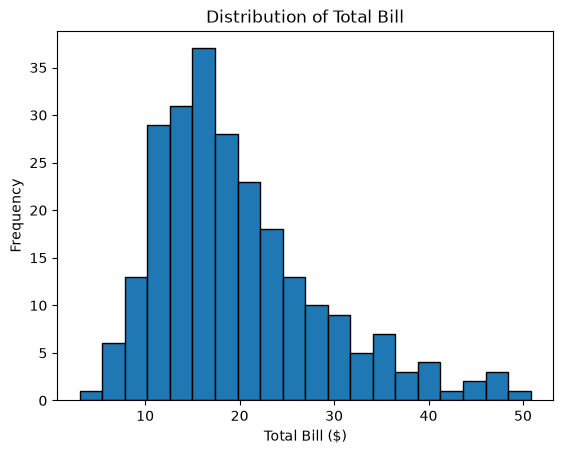

In [25]:
plt.hist(tips['total_bill'], bins=20, edgecolor='black')
plt.title('Distribution of Total Bill')
plt.xlabel('Total Bill ($)')
plt.ylabel('Frequency')
plt.show()

# COMMENT: The distribution of total_bill is unimodal and right-skewed 
# (positively skewed). Most bills fall between roughly $10 and $25, with 
# the peak around $15 to $20. The right tail stretches out toward $50, 
# meaning a small number of large bills pull the mean (about $19.79) above 
# the median (about $17.80). There are no bills near zero, since the 
# minimum is about $3.

### Exercise 2(d) (5 points)

Create a side-by-side boxplot of `total_bill` based on the day of the week.

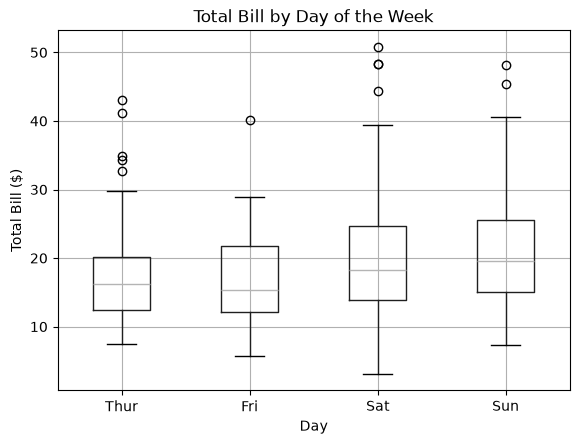

In [31]:
# Created categorical so the days of the week are in order in the boxplot.
# Pandas would natively sort the days alphabetically, which is not what we want 
# for this analysis.
tips['day'] = pd.Categorical(tips['day'],
                             categories=['Thur', 'Fri', 'Sat', 'Sun'],
                             ordered=True)

tips.boxplot(column='total_bill', by='day')
plt.title('Total Bill by Day of the Week')
plt.suptitle('')
plt.xlabel('Day')
plt.ylabel('Total Bill ($)')
plt.show()

### Exercise 2(e) (5 points)

Create a scatter-plot of `total_bill` and `tip`. Describe the plot.

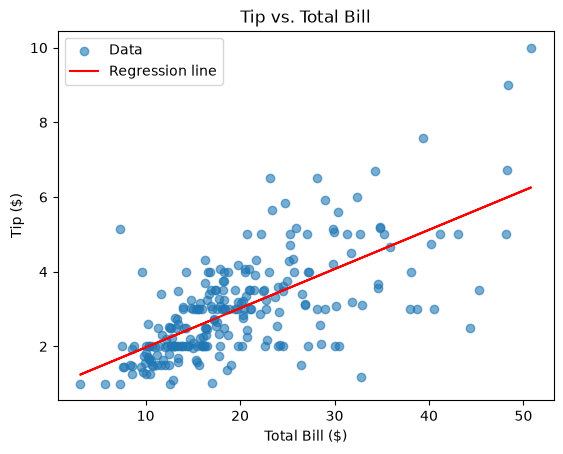

tip = 0.920 + 0.105 * total_bill
Correlation: 0.676


In [ ]:
#plt.scatter(tips['total_bill'], tips['tip'], alpha=0.6)
#plt.title('Tip vs. Total Bill')
#plt.xlabel('Total Bill ($)')
#plt.show()

x = tips['total_bill']
y = tips['tip']

# Least-squares regression line
slope = x.cov(y) / x.var()
intercept = y.mean() - slope * x.mean()

plt.scatter(x, y, alpha=0.6, label='Data')
plt.plot(x, intercept + slope * x, color='red', label='Regression line')
plt.title('Tip vs. Total Bill')
plt.xlabel('Total Bill ($)')
plt.ylabel('Tip ($)')
plt.legend()
plt.show()

print(f'tip = {intercept:.3f} + {slope:.3f} * total_bill')
print(f'Correlation: {x.corr(y):.3f}')

# DESCRIBE: The scatter plot shows a positive, roughly linear relationship 
# between total_bill and tip: as the bill increases, the tip generally increases 
# too. The relationship is moderately strong (correlation of about 0.68). Most
# points are clustered at bills between $10 and $25 with tips of $2 to $4. 
# The spread of tips widens as the bill grows, so larger bills have more 
# variation in how much people tip. A few points stand out as possible outliers, 
# such as a large tip of $10 on a bill around $50, and some low tips on bills above $30.

# Exercise 3

In this exercise, we will practice debugging a data cleaning script written for the `tips.csv` data file. A colleague wrote the code below to compute the tip percentage (`tip` divided by `total_bill`, times 100) and compare it across days, but it contains several bugs.

```
import pandas as pd

tips = pd.read_csv('tips.csv')

# Step 1: tip percentage
tips['tip_pct'] = tips['tip'] / tips['Total_Bill'] * 100

# Step 2: average tip percentage by day
avg_by_day = tips.groupby('day')['tip_pct'].mean()
print('Average tip % on Saturday: ' + avg_by_day['Sat'])

# Step 3: weekend orders only
weekend = tips[(tips['day'] == 'Sat') or (tips['day'] == 'Sun')]
print(weekend.shape)
```

### Exercise 3(a) (4 points)

Run Step 1 in the cell below. Read the error message: what type of error is it, which line causes it, and why? Fix the code so that it runs.

In [ ]:
import pandas as pd

tips = pd.read_csv('tips.csv')

# Original Step 1: tip percentage
#tips['tip_pct'] = tips['tip'] / tips['Total_Bill'] * 100

# Step 1: tip percentage (fixed column name is case sensitive)
tips['tip_pct'] = tips['tip'] / tips['total_bill'] * 100
print(tips.head())

   total_bill   tip     sex smoker  day    time  size    tip_pct
0       16.99  1.01  Female     No  Sun  Dinner     2   5.944673
1       10.34  1.66    Male     No  Sun  Dinner     3  16.054159
2       21.01  3.50    Male     No  Sun  Dinner     3  16.658734
3       23.68  3.31    Male     No  Sun  Dinner     2  13.978041
4       24.59  3.61  Female     No  Sun  Dinner     4  14.680765


### Exercise 3(b) (4 points)

Run Step 2. Read the error message, explain what went wrong, and fix the code so that it prints the average tip percentage on Saturday rounded to two decimals.

In [44]:
# Original Step 2: average tip percentage by day
avg_by_day = tips.groupby('day')['tip_pct'].mean()
#print('Average tip % on Saturday: ' + avg_by_day['Sat'])

# Fix: Convert the number to a string with str()
print('Average tip % on Saturday: ' + str(round(avg_by_day['Sat'], 2)))

# What went wrong?  The text and the avg_by_day are different types (str and float)

Average tip % on Saturday: 15.32


### Exercise 3(c) (4 points)

Run Step 3. Read the error message, explain what went wrong, and fix the code so that `weekend` contains only the Saturday and Sunday orders.

In [ ]:
# Orignial Step 3: weekend orders only
#weekend = tips[(tips['day'] == 'Sat') or (tips['day'] == 'Sun')]
#print(weekend.shape)

# Fixed Step 3: weekend orders only
weekend = tips[(tips['day'] == 'Sat') | (tips['day'] == 'Sun')]
print(weekend.shape)

# What went wrong?  Syntax error. 'or' in pandas is not valid.
# changed it to " |" (pipe) character.

(163, 8)


### Exercise 3(d) (4 points)

Not every bug raises an error. Use `.describe()` on `tip_pct` and `.isna().sum()` on `tips` to check that your results are reasonable (for example, tip percentages should be between 0 and 100 and there should be no missing values). Then use an `assert` statement to verify that `weekend` contains only `'Sat'` and `'Sun'`. Summarize what you found.

In [ ]:
# Check 1: summary statistics for tip_pct
print(tips['tip_pct'].describe())

# Check 2: count missing values in every column
print(tips.isna().sum())

# Check 3: confirm weekend only contains Saturday and Sunday
assert set(weekend['day'].unique()) == {'Sat', 'Sun'}, 'weekend contains days other than Sat and Sun'
print('Assert passed: weekend contains only Sat and Sun')

# What I found:
#
# 1. tip_pct.describe(): all 244 rows have a value. Tip percentages
#    range from about 3.56% to 71.03%, so every value falls between
#    0 and 100, as expected. The mean is about 16.08% and the median
#    about 15.48%, which is a typical tipping rate. The maximum of
#    71.03% (a $5.17 tip on a $7.25 bill) is unusually high and is
#    a likely outlier, but it is a plausible real value, not a bug.
#
# 2. tips.isna().sum(): every column shows 0, so there are no missing
#    values in the data or in the new tip_pct column.
#
# 3. The assert passed silently, confirming that the weekend filter
#    from Step 3 kept only 'Sat' and 'Sun' rows (163 rows in total).
#
# Conclusion: after fixing the three bugs, the script produces
# reasonable results with no hidden errors in the data.
# ---------------------------------------------------------------

count    244.000000
mean      16.080258
std        6.107220
min        3.563814
25%       12.912736
50%       15.476977
75%       19.147549
max       71.034483
Name: tip_pct, dtype: float64
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
tip_pct       0
dtype: int64
Assert passed: weekend contains only Sat and Sun
